# Роль 2: Предсказание успеха партии по первым k шагам


In [1]:
# Настройка окружения для Google Colab
import os, sys
from pathlib import Path

if "google.colab" in sys.modules:
    REPO_DIR = Path("/content/wikispeedia")
    if not REPO_DIR.exists():
        !git clone https://github.com/sammdog/wikispeedia.git /content/wikispeedia
        %cd /content/wikispeedia
        !pip install -q -r requirements.txt
        !python scripts/download_dataset.py
        !python scripts/build_dataset.py
    else:
        %cd /content/wikispeedia


In [2]:
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.preprocessing import StandardScaler

ROOT = Path("/content/wikispeedia") if "google.colab" in sys.modules else (Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.config import PROCESSED_DIR, FIGURES_DIR

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (10, 4.5)


## 1. Загрузка данных и подготовка признаков статей


In [3]:
paths = pd.read_parquet(PROCESSED_DIR / "paths.parquet")
nodes = pd.read_parquet(PROCESSED_DIR / "node_features.parquet").set_index("article")
D = np.load(PROCESSED_DIR / "distance_matrix.npy")
with open(PROCESSED_DIR / "article_to_idx.json", encoding="utf-8") as f:
    article_to_idx = json.load(f)

# Преобразуем признаки статей в быстрые словари для оптимизации циклов
in_deg_map = nodes["in_degree"].to_dict()
out_deg_map = nodes["out_degree"].to_dict()
pr_map = nodes["pagerank"].to_dict()
drop_map = nodes["drop_rate_train"].to_dict()

print(f"Загружено партий: {len(paths):,} (train={sum(paths['split']=='train'):,}, val={sum(paths['split']=='val'):,}, test={sum(paths['split']=='test'):,})")


Загружено партий: 76,193 (train=56,203, val=9,721, test=10,269)


## 2. Функция извлечения признаков по префиксу k (с честным is_back)


In [4]:
def extract_features(trace, is_back, target, k=5):
    # Предотвращение утечек:
    # 1. Отбрасываем пути короче k шагов (фикс утечки длины!)
    # 2. Отбрасываем пути, где цель уже достигнута в первые k шагов
    if len(trace) < k + 1 or target in trace[:k + 1]:
        return None
    
    prefix = trace[:k + 1]
    curr = prefix[-1]
    start = prefix[0]
    
    d_curr = D[article_to_idx[curr], article_to_idx[target]] if (curr in article_to_idx and target in article_to_idx) else 99
    d_start = D[article_to_idx[start], article_to_idx[target]] if (start in article_to_idx and target in article_to_idx) else 99
    
    if d_curr == -1: d_curr = 99
    if d_start == -1: d_start = 99
    
    all_dists = [
        D[article_to_idx[a], article_to_idx[target]]
        for a in prefix
        if a in article_to_idx and target in article_to_idx and D[article_to_idx[a], article_to_idx[target]] != -1
    ]
    d_min = min(all_dists) if all_dists else 99
    
    return {
        "k": k,
        "dist_last": d_curr,
        "dist_min": d_min,
        "dist_first": d_start,
        "dist_delta": d_start - d_curr,  # >0: приближаемся к цели
        "in_degree_last": in_deg_map.get(curr, 0),
        "out_degree_last": out_deg_map.get(curr, 0),
        "pagerank_last": pr_map.get(curr, 0.0),
        "drop_rate_last": drop_map.get(curr, 0.0),
        "back_clicks": int(sum(is_back[:k + 1])),  # честный подсчёт возвратов по флагу is_back!
    }

def get_dataset_for_k(k):
    train_data, val_data = [], []
    for trace, is_back, target, finished, split in zip(
        paths["trace"], paths["is_back"], paths["target"], paths["finished"], paths["split"]
    ):
        if split not in ("train", "val"):
            continue
        f = extract_features(trace, is_back, target, k=k)
        if f is not None:
            f["label"] = finished
            if split == "train":
                train_data.append(f)
            else:
                val_data.append(f)
    return pd.DataFrame(train_data), pd.DataFrame(val_data)

# Проверка на k=5
df_tr5, df_val5 = get_dataset_for_k(5)
print(f"Пример для k=5: train shape={df_tr5.shape}, val shape={df_val5.shape}")
print(f"Среднее число back_clicks в train: {df_tr5['back_clicks'].mean():.3f}")


Пример для k=5: train shape=(20086, 11), val shape=(3577, 11)
Среднее число back_clicks в train: 0.398


## 3. Базовые модели (k=5): Logistic Regression и HistGradientBoosting


Результаты валидации (k=5, разбиение по target):
  Logistic Regression ROC-AUC: 0.7815
  HistGradientBoosting ROC-AUC: 0.7863

=== Веса признаков Logistic Regression (отсортированы) ===
        feature      coef
     dist_delta  0.808886
 in_degree_last  0.252353
    back_clicks  0.153595
out_degree_last -0.163689
 drop_rate_last -0.200996
  pagerank_last -0.205308
       dist_min -0.787652
     dist_first -0.819759
      dist_last -1.176875


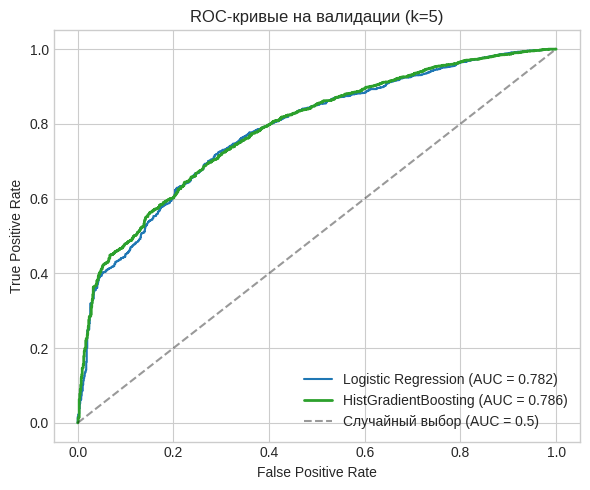

In [5]:
feature_cols = [c for c in df_tr5.columns if c not in ("label", "k")]

X_train, y_train = df_tr5[feature_cols], df_tr5["label"]
X_val, y_val = df_val5[feature_cols], df_val5["label"]

# Масштабирование для логистической регрессии
scaler = StandardScaler()
X_tr_s = scaler.fit_transform(X_train)
X_val_s = scaler.transform(X_val)

# 1. Логистическая регрессия
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_tr_s, y_train)
y_pred_lr = lr.predict_proba(X_val_s)[:, 1]
auc_lr = roc_auc_score(y_val, y_pred_lr)

# 2. Градиентный бустинг
hgb = HistGradientBoostingClassifier(random_state=42)
hgb.fit(X_train, y_train)
y_pred_hgb = hgb.predict_proba(X_val)[:, 1]
auc_hgb = roc_auc_score(y_val, y_pred_hgb)

print(f"Результаты валидации (k=5, разбиение по target):")
print(f"  Logistic Regression ROC-AUC: {auc_lr:.4f}")
print(f"  HistGradientBoosting ROC-AUC: {auc_hgb:.4f}")

# Вывод отсортированных весов признаков (важность в логистической регрессии)
coef_df = pd.DataFrame({"feature": feature_cols, "coef": lr.coef_[0]}).sort_values("coef", ascending=False)
print("\n=== Веса признаков Logistic Regression (отсортированы) ===")
print(coef_df.to_string(index=False))

# График ROC-кривой
plt.figure(figsize=(6, 5))
fpr_lr, tpr_lr, _ = roc_curve(y_val, y_pred_lr)
fpr_hgb, tpr_hgb, _ = roc_curve(y_val, y_pred_hgb)

plt.plot(fpr_lr, tpr_lr, label=f"Logistic Regression (AUC = {auc_lr:.3f})", color="tab:blue")
plt.plot(fpr_hgb, tpr_hgb, label=f"HistGradientBoosting (AUC = {auc_hgb:.3f})", color="tab:green", linewidth=2)
plt.plot([0, 1], [0, 1], "k--", alpha=0.4, label="Случайный выбор (AUC = 0.5)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-кривые на валидации (k=5)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


## 4. Качество предсказания в зависимости от длины префикса k


Обучение моделей для k in [1, 2, 3, 4, 5, 6, 8, 10]...


  k= 1 | Train: 51758 | Val: 8966 | LR ROC-AUC: 0.6725 | HGB ROC-AUC: 0.6876


  k= 2 | Train: 46800 | Val: 8148 | LR ROC-AUC: 0.7318 | HGB ROC-AUC: 0.7356


  k= 3 | Train: 38112 | Val: 6645 | LR ROC-AUC: 0.7549 | HGB ROC-AUC: 0.7657


  k= 4 | Train: 27848 | Val: 4950 | LR ROC-AUC: 0.7733 | HGB ROC-AUC: 0.7794


  k= 5 | Train: 20086 | Val: 3577 | LR ROC-AUC: 0.7815 | HGB ROC-AUC: 0.7863


  k= 6 | Train: 14473 | Val: 2558 | LR ROC-AUC: 0.7804 | HGB ROC-AUC: 0.7829


  k= 8 | Train:  7927 | Val: 1350 | LR ROC-AUC: 0.7582 | HGB ROC-AUC: 0.7610


  k=10 | Train:  4720 | Val:  820 | LR ROC-AUC: 0.7497 | HGB ROC-AUC: 0.7153


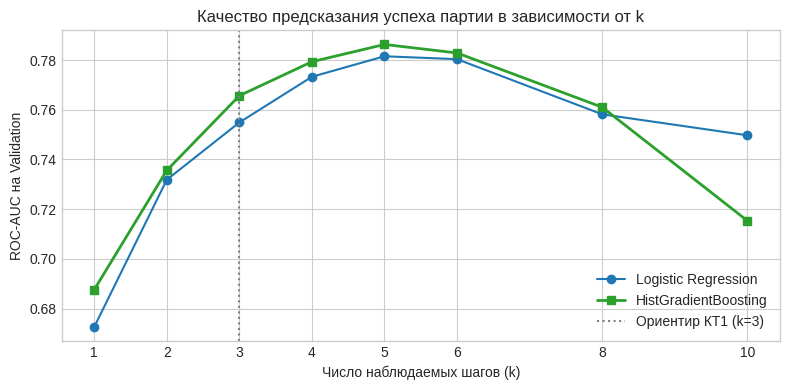

In [6]:
ks = [1, 2, 3, 4, 5, 6, 8, 10]
results = []

print("Обучение моделей для k in [1, 2, 3, 4, 5, 6, 8, 10]...")
for k in ks:
    tr, val = get_dataset_for_k(k)
    X_tr, y_tr = tr[feature_cols], tr["label"]
    X_v, y_v = val[feature_cols], val["label"]
    
    # LR
    sc = StandardScaler()
    X_tr_s = sc.fit_transform(X_tr)
    X_v_s = sc.transform(X_v)
    m_lr = LogisticRegression(max_iter=1000, random_state=42).fit(X_tr_s, y_tr)
    auc_lr_k = roc_auc_score(y_v, m_lr.predict_proba(X_v_s)[:, 1])
    
    # HGB
    m_hgb = HistGradientBoostingClassifier(random_state=42).fit(X_tr, y_tr)
    auc_hgb_k = roc_auc_score(y_v, m_hgb.predict_proba(X_v)[:, 1])
    
    results.append({"k": k, "auc_lr": auc_lr_k, "auc_hgb": auc_hgb_k, "n_train": len(tr), "n_val": len(val)})
    print(f"  k={k:2d} | Train: {len(tr):5d} | Val: {len(val):4d} | LR ROC-AUC: {auc_lr_k:.4f} | HGB ROC-AUC: {auc_hgb_k:.4f}")

res_df = pd.DataFrame(results)

# График ROC-AUC от k
plt.figure(figsize=(8, 4))
plt.plot(res_df["k"], res_df["auc_lr"], marker="o", label="Logistic Regression", color="tab:blue")
plt.plot(res_df["k"], res_df["auc_hgb"], marker="s", label="HistGradientBoosting", color="tab:green", linewidth=2)
plt.axvline(3, color="gray", linestyle=":", label="Ориентир КТ1 (k=3)")
plt.xlabel("Число наблюдаемых шагов (k)")
plt.ylabel("ROC-AUC на Validation")
plt.title("Качество предсказания успеха партии в зависимости от k")
plt.xticks(ks)
plt.legend()
plt.tight_layout()
plt.show()
